# 📚 PyTorch Practice Notebook - Lecture 1 Exercises

**Based on:** SAIR PyTorch Mastery - Lecture 1: From NumPy to Production Neural Networks

**Instructions:** Complete the exercises below to test your understanding of PyTorch fundamentals. Try to solve them without looking at the original notebook first!

## 🔧 Setup & Imports

Run this cell first to set up your environment.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.14.0
CUDA available: False


## 🎯 Exercise 1: Understanding Tensors & Autograd

### Part A: Manual Gradient Verification

**Task:** Create a simple computation graph and compute gradients both manually and with PyTorch's autograd.

Given:
- x = 3.0
- w = 2.0  
- b = 1.0

Compute: y = w*x + b, then loss = y²

**Your job:**
1. Create PyTorch tensors with gradient tracking
2. Compute the forward pass
3. Compute gradients using `.backward()`
4. Verify by manually computing ∂loss/∂w and ∂loss/∂x using chain rule

In [ ]:
# =========== YOUR CODE HERE ===========
# Create tensors with requires_grad=True

# Forward pass: y = w*x + b, loss = y²

# Backward pass

# Print gradients

# Manual verification
# Compute manually: ∂loss/∂w = ? and ∂loss/∂x = ?
# =========================================

In [2]:
# =========== YOUR CODE HERE ===========
# Create tensors with requires_grad=True

x = torch.tensor([3.0] , requires_grad=True)
w = torch.tensor([2.0] , requires_grad=True)
b = torch.tensor([1.0] , requires_grad=True)

# Forward pass: y = w*x + b, loss = y²

d = x * w

y = d + b

loss = y**2

# Backward pass

loss.backward()

# Print gradients

print(x.grad.item())
print(w.grad.item())
print(b.grad.item())

# Manual verification
# Compute manually: ∂loss/∂w = ? and ∂loss/∂x = ?
# =========================================

dloss_dy = 2*y
dd_dx = w 
dd_dw = x
dy_db = 1
dy_dd = 1
dloss_dw = dloss_dy * dy_dd * dd_dw
dloss_dx = dloss_dy * dy_dd * dd_dx
dloss_db = dloss_dy * dy_db


print(dloss_dx)
print(dloss_dw)
print(dloss_db)

28.0
42.0
14.0
tensor([28.], grad_fn=<MulBackward0>)
tensor([42.], grad_fn=<MulBackward0>)
tensor([14.], grad_fn=<MulBackward0>)


### Part B: Gradient Accumulation Demonstration

**Task:** Show what happens when you forget `optimizer.zero_grad()`.

1. Create a simple linear model
2. Run two training steps WITHOUT zero_grad
3. Show that gradients accumulate
4. Fix by adding zero_grad

In [ ]:
# =========== YOUR CODE HERE ===========
# Create a simple model
# model = nn.Linear(3, 1)

# Create dummy data
# X = torch.randn(5, 3)
# y = torch.randn(5, 1)

# Create optimizer
# optimizer = optim.SGD(model.parameters(), lr=0.01)

# First forward-backward (no zero_grad)
# Print gradient after first iteration

# Second forward-backward (no zero_grad)
# Print gradient after second iteration

# Show that gradients doubled!

# Now do it correctly with zero_grad
# =========================================

In [3]:
# =========== YOUR CODE HERE ===========
# Create a simple model
model = nn.Linear(3, 1)


# Create dummy data
X = torch.randn(5, 3 , requires_grad=True)
y = torch.randn(5, 1 , requires_grad=True)


optimizer = optim.SGD(model.parameters(), lr=0.01)

y_hat = model(X)

first_loss = ((y-y_hat)**2).mean()

first_loss.backward()

# Create optimizer

# First forward-backward (no zero_grad)
optimizer.step()
# Print gradient after first iteration

print(model.weight.grad)

# Second forward-backward (no zero_grad)
y_hat = model(X)

second_loss = ((y_hat - y)**2).mean()

second_loss.backward()

optimizer.step()
# Print gradient after second iteration

# Show that gradients doubled!

print(model.weight.grad)


# Now do it correctly with zero_grad
# =======================================================================

y_hat = model(X)

first_loss = ((y-y_hat)**2).mean()

optimizer.zero_grad()

first_loss.backward()

# Create optimizer

# First forward-backward (no zero_grad)
optimizer.step()
# Print gradient after first iteration

print(model.weight.grad)


# Second forward-backward (no zero_grad)
y_hat = model(X)

second_loss = ((y_hat - y)**2).mean()

second_loss.backward()

optimizer.step()
# Print gradient after second iteration

# Show that gradients doubled!

print(model.weight.grad)

tensor([[ 0.3354,  2.2668, -0.6727]])
tensor([[ 0.6617,  4.4332, -1.2948]])
tensor([[ 0.3088,  1.9703, -0.5238]])
tensor([[ 0.6102,  3.8543, -1.0053]])


## 🏗️ Exercise 2: Building Neural Networks with nn.Module

### Part A: Convert NumPy Network to PyTorch

**Task:** Convert this NumPy-style network to PyTorch using `nn.Module`.

Original NumPy network:
```python
class NumPyNetwork:
    def __init__(self):
        self.W1 = np.random.randn(10, 20)
        self.b1 = np.zeros(20)
        self.W2 = np.random.randn(20, 5)
        self.b2 = np.zeros(5)
        
    def forward(self, X):
        z1 = X @ self.W1 + self.b1
        a1 = np.maximum(0, z1)  # ReLU
        z2 = a1 @ self.W2 + self.b2
        return z2
```

Create a PyTorch version with:
1. Proper inheritance from `nn.Module`
2. PyTorch layers instead of manual weights
3. ReLU activation
4. Forward method

In [ ]:
# =========== YOUR CODE HERE ===========
class PyTorchNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        # Define layers here
        
    def forward(self, x):
        # Implement forward pass
        pass
# =========================================

In [5]:
# =========== YOUR CODE HERE ===========
class PyTorchNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(10,20)
        self.relu = nn.ReLU(inplace=True)
        self.layer2 = nn.Linear(20,5)
        
    def forward(self, x):
        layer1_output = self.layer1(x)
        relu_output = self.relu(layer1_output)
        layer2_output = self.layer2(relu_output)
        return layer2_output
# =========================================

### Part B: Test Your Network

Test that your network works correctly:

In [6]:
# Test your network
model = PyTorchNetwork()

# Create dummy input
X_test = torch.randn(8, 10)  # batch_size=8, features=10

# Forward pass
output = model(X_test)

print(f"Input shape: {X_test.shape}")
print(f"Output shape: {output.shape}")
print(f"Output range: [{output.min():.3f}, {output.max():.3f}]")

Input shape: torch.Size([8, 10])
Output shape: torch.Size([8, 5])
Output range: [-0.624, 0.480]


## 🔄 Exercise 3: Complete Training Loop

### Part A: Fix the Buggy Training Loop

**Task:** This training loop has several bugs. Identify and fix them all.

In [ ]:
# =========== BUGGY CODE - FIX ME! ===========
class BuggyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(5, 10)
        self.layer2 = nn.Linear(10, 1)
    
    def forward(self, x):
        x = torch.relu(self.layer1(x))
        return self.layer2(x)

# Create model and optimizer
model = BuggyNet()
optimizer = optim.Adam(model.parameters())

# Dummy data
X = torch.randn(100, 5)
y = torch.randn(100, 1)

# Training loop with bugs
losses = []
for epoch in range(50):
    # Forward pass
    predictions = model(X)
    loss = ((predictions - y) ** 2).mean()
    losses.append(loss.item())
    
    # Backward pass
    loss.backward()
    optimizer.step()
    
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.4f}")

# Plot results
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss (Should Decrease!)')
plt.show()
# ============================================

Epoch 0: Loss = 1.3251
Epoch 10: Loss = 1.2775
Epoch 20: Loss = 1.2377
Epoch 30: Loss = 1.2060
Epoch 40: Loss = 1.1807


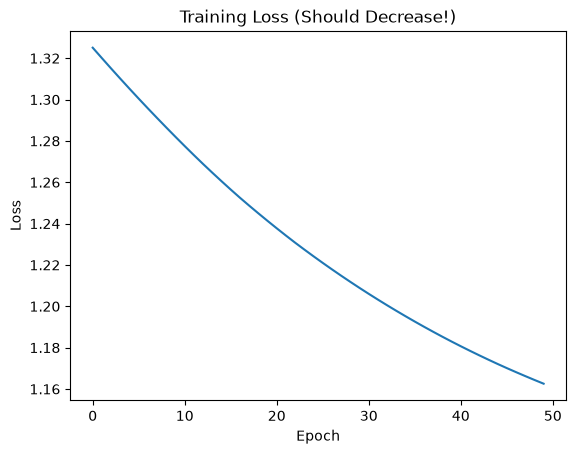

In [7]:
# =========== BUGGY CODE - FIX ME! ===========
class BuggyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(5, 10)
        self.layer2 = nn.Linear(10, 1)
        self.relu = nn.ReLU()
    
    def forward(self, x):
        x = self.relu(self.layer1(x))
        return self.layer2(x)

# Create model and optimizer
model = BuggyNet()
optimizer = optim.Adam(model.parameters())

# Dummy data
X = torch.randn(100, 5)
y = torch.randn(100, 1)

# Training loop with bugs
losses = []
for epoch in range(50):
    # Forward pass
    predictions = model(X)
    loss = ((predictions - y) ** 2).mean()
    losses.append(loss.item())
    
    optimizer.zero_grad()

    # Backward pass
    loss.backward()
    optimizer.step()

    
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.4f}")

# Plot results
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss (Should Decrease!)')
plt.show()
# ============================================

### Part B: Write a Correct Training Loop

**Task:** Write a complete, correct training loop from scratch for a regression problem.

Requirements:
1. Create a neural network with 2 hidden layers
2. Use proper loss function for regression
3. Include all 6 training steps
4. Track and plot loss
5. Make it device-agnostic

In [ ]:
# =========== YOUR CODE HERE ===========
# 1. Define your network architecture

# 2. Set device (CPU or GPU)

# 3. Create dummy data
# X = torch.randn(200, 7)  # 200 samples, 7 features
# y = torch.randn(200, 1)  # 200 target values

# 4. Initialize model, loss function, optimizer

# 5. Training loop (100 epochs)
# losses = []
# for epoch in range(100):
#     # Training steps here...
#     pass

# 6. Plot loss curve
# =========================================

## 💾 Exercise 4: Model Persistence

### Part A: Save and Load Model Weights

**Task:** Train a simple model, save it, load it into a new model, and verify they produce identical predictions.

In [ ]:
# =========== YOUR CODE HERE ===========
# 1. Create and train a simple model
# model = nn.Sequential(
#     nn.Linear(4, 10),
#     nn.ReLU(),
#     nn.Linear(10, 1)
# )

# 2. Train for a few epochs

# 3. Save model weights

# 4. Create a NEW model with same architecture
# new_model = ...

# 5. Load saved weights into new model

# 6. Verify predictions match
# test_input = torch.randn(5, 4)
# original_pred = model(test_input)
# loaded_pred = new_model(test_input)
# print(f"Predictions match: {torch.allclose(original_pred, loaded_pred, rtol=1e-4)}")
# =========================================

In [8]:
# =========== YOUR CODE HERE ===========
# 1. Create and train a simple model

test_input = torch.randn(5, 4)
test_output = torch.randn(5, 1)

model = nn.Sequential(
    nn.Linear(4, 10),
    nn.ReLU(),
    nn.Linear(10, 1)
)

criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters() , 0.01)

# 2. Train for a few epochs

for epoch in range(5):
    result = model(test_input)
    loss = criterion(result , test_output)

    model.zero_grad()
    loss.backward()

    optimizer.step()

# 3. Save model weights

torch.save(model.state_dict() , 'ash_weights.pth')

# 4. Create a NEW model with same architecture
# new_model = ...

new_model = nn.Sequential(
    nn.Linear(4, 10),
    nn.ReLU(),
    nn.Linear(10, 1)
)

# 5. Load saved weights into new model
loaded_weights = torch.load('ash_weights.pth')
new_model.load_state_dict(loaded_weights)

# 6. Verify predictions match
original_pred = model(test_input)
loaded_pred = new_model(test_input)
print(f"Predictions match: {torch.allclose(original_pred, loaded_pred, rtol=1e-4)}")
# =========================================

Predictions match: True


### Part B: Create Training Checkpoints

**Task:** Save a checkpoint that allows resuming training. Include:
- Model state_dict
- Optimizer state_dict
- Epoch number
- Loss value

Then demonstrate loading and resuming training.

In [ ]:
# =========== YOUR CODE HERE ===========
# 1. Train a model for 30 epochs

# 2. Create checkpoint dictionary
# checkpoint = {
#     'epoch': 30,
#     'model_state_dict': ...,
#     'optimizer_state_dict': ...,
#     'loss': ...,
# }

# 3. Save checkpoint

# 4. Create new model and optimizer

# 5. Load checkpoint

# 6. Resume training from epoch 30
# for epoch in range(checkpoint['epoch'], 60):
#     # Training loop
#     print(f"Resumed training at epoch {epoch}")
# =========================================

In [9]:
# =========== YOUR CODE HERE ===========
# 1. Train a model for 30 epochs

test_input = torch.randn(5, 4)
test_output = torch.randn(5, 1)

model = nn.Sequential(
    nn.Linear(4, 10),
    nn.ReLU(),
    nn.Linear(10, 1)
)

criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters() , 0.01)



for epoch in range(30):
    result = model(test_input)
    loss = criterion(result , test_output)

    model.zero_grad()
    loss.backward()

    optimizer.step()



# 2. Create checkpoint dictionary
checkpoint = {
    'epoch': 30,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss': loss.item(),
}

# 3. Save checkpoint

torch.save(checkpoint ,'checkpoint.pth')

# 4. Create new model and optimizer


model = nn.Sequential(
    nn.Linear(4, 10),
    nn.ReLU(),
    nn.Linear(10, 1)
)

optimizer = optim.SGD(model.parameters() , 0.01)

# 5. Load checkpoint

checkpoint = torch.load('checkpoint.pth')

model.load_state_dict(checkpoint['model_state_dict'])

optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

# 6. Resume training from epoch 30
for epoch in range(checkpoint['epoch'], 60):

    result = model(test_input)
    loss = criterion(result , test_output)

    model.zero_grad()
    loss.backward()

    optimizer.step()
    
    print(f"Resumed training at epoch {epoch}")
# =========================================

Resumed training at epoch 30
Resumed training at epoch 31
Resumed training at epoch 32
Resumed training at epoch 33
Resumed training at epoch 34
Resumed training at epoch 35
Resumed training at epoch 36
Resumed training at epoch 37
Resumed training at epoch 38
Resumed training at epoch 39
Resumed training at epoch 40
Resumed training at epoch 41
Resumed training at epoch 42
Resumed training at epoch 43
Resumed training at epoch 44
Resumed training at epoch 45
Resumed training at epoch 46
Resumed training at epoch 47
Resumed training at epoch 48
Resumed training at epoch 49
Resumed training at epoch 50
Resumed training at epoch 51
Resumed training at epoch 52
Resumed training at epoch 53
Resumed training at epoch 54
Resumed training at epoch 55
Resumed training at epoch 56
Resumed training at epoch 57
Resumed training at epoch 58
Resumed training at epoch 59


## 🚀 Exercise 5: Real-World Application

### Part A: Boston Housing Prediction

**Task:** Use PyTorch to predict Boston housing prices.

Steps:
1. Load Boston housing dataset
2. Split into train/test
3. Standardize features
4. Create PyTorch model
5. Train model
6. Evaluate on test set

In [ ]:
from sklearn.datasets import load_boston
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# =========== YOUR CODE HERE ===========
# 1. Load dataset
# boston = load_boston()
# X, y = boston.data, boston.target

# 2. Split data (80% train, 20% test)

# 3. Standardize features

# 4. Convert to PyTorch tensors
# X_train_tensor = ...
# y_train_tensor = ...

# 5. Define model architecture
# class BostonPredictor(nn.Module):
#     def __init__(self, input_size):
#         super().__init__()
#         # Define layers
        
#     def forward(self, x):
#         # Forward pass

# 6. Create model instance
# model = BostonPredictor(input_size=X_train.shape[1])

# 7. Training loop
# ...

# 8. Evaluate on test set
# model.eval()
# with torch.no_grad():
#     test_predictions = model(X_test_tensor)
#     test_loss = nn.MSELoss()(test_predictions, y_test_tensor)
#     print(f"Test Loss: {test_loss.item():.4f}")

# 9. Plot predictions vs actual
# plt.scatter(y_test_tensor.numpy(), test_predictions.numpy())
# plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
# plt.xlabel('Actual Prices')
# plt.ylabel('Predicted Prices')
# plt.title('Boston Housing Predictions')
# plt.show()
# =========================================

Accuracy: 42.11%


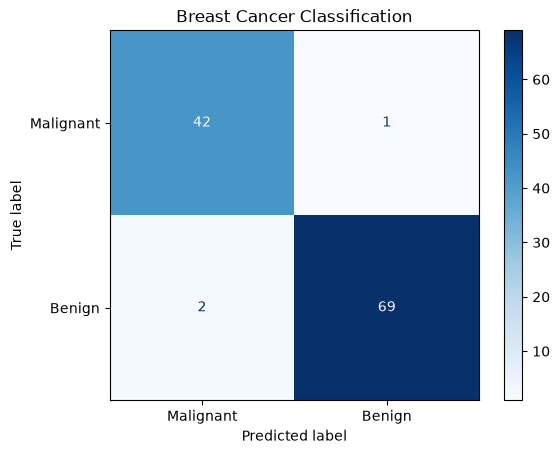

In [10]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# =========== YOUR CODE HERE ===========
# 1. Load dataset
boston = load_breast_cancer()
X, y = boston.data, boston.target

# 2. Split data (80% train, 20% test)

X_train , X_test , Y_train , Y_test = train_test_split(X , y , test_size=0.2 , train_size=0.8 , random_state=42 , shuffle=True)


# 3. Standardize features

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Convert to PyTorch tensors
X_train = torch.tensor(X_train , dtype=torch.float32)
Y_train = torch.tensor(Y_train , dtype=torch.float32).reshape(-1,1)

X_test = torch.tensor(X_test , dtype=torch.float32)
Y_test = torch.tensor(Y_test , dtype=torch.float32).reshape(-1,1)

# 5. Define model architecture
class BostonPredictor(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.layer1 = nn.Linear(input_size , 16)
        self.relu = nn.ReLU()
        self.layer2 = nn.Linear(16 , 8)
        self.layer3 = nn.Linear(8 , 1)
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.layer3(x)
        return self.sigmoid(x)

# 6. Create model instance
model = BostonPredictor(input_size=X_train.shape[1])

device = "mps" if torch.backends.mps.is_available() else "cpu"

model.to(device)

X_train = X_train.to(device)
Y_train = Y_train.to(device)

X_test = X_test.to(device)
Y_test = Y_test.to(device)

# 7. Training loop

optimizer = optim.Adam(model.parameters() , 0.01)
criterion = nn.BCELoss()

model.train()

losses = []

for epoch in range(500):
    result = model(X_train)

    loss = criterion(result , Y_train )

    model.zero_grad()

    loss.backward()

    losses.append(loss.item())

    optimizer.step()




# 8. Evaluate on test set
model.eval()
with torch.no_grad():
    test_prob = model(X_test)
    test_loss = nn.BCELoss()(test_prob, Y_test)
    accuracy = (test_prob == Y_test).float().mean()
    print(f"Accuracy: {accuracy.item():.2%}")

torch.save(model.state_dict() , 'breast_cancer.pth')

# 9. Plot predictions vs actual

# Convert probabilities to binary classes (0 or 1)
y_pred = (test_prob >= 0.5).int().cpu().numpy().flatten()
y_true = Y_test.cpu().numpy().flatten().astype(int)




# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

disp.plot(cmap="Blues")
plt.title("Breast Cancer Classification")
plt.show()
# =========================================

## 🧪 Challenge Problems

### Challenge 1: Debug a Non-Training Model

Create a model that SHOULD learn but doesn't (loss stays constant). Include at least 3 common bugs. Then write debugging code to identify each bug.

In [ ]:
# =========== CHALLENGE 1 ===========
# Create a buggy model
class BuggyModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Add bugs here
        
    def forward(self, x):
        # Add bugs here
        pass

# Debugging function
def debug_model(model, X, y):
    """Identify why model isn't training"""
    print("Debugging Model...")
    
    # Check 1: Are gradients being computed?
    
    # Check 2: Are parameters updating?
    
    # Check 3: Is loss changing?
    
    # Check 4: Are weights reasonable?
    
    # Check 5: Is learning rate appropriate?
    
    print("Debugging complete!")

# Create and debug model
# model = BuggyModel()
# debug_model(model, X, y)
# ===================================

In [11]:
# =========== CHALLENGE 1 ===========
# Create a buggy model


class BuggyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(4 , 16)
        self.relu = nn.ReLU()
        self.layer2 = nn.Linear(16 , 1)
        
    def forward(self, x):
        return self.layer2(self.relu(self.layer1(x)))


# Debugging function
def debug_model(model, X, y):
    """Identify why model isn't training"""
    print("Debugging Model...")

    result = model(X)

    loss = criterion(result , y)

    model.zero_grad()

    # check 1
    loss.backward()

    optimizer.step()

    
    # Check 1: Are gradients being computed?

    noncomputed_grad_count_found = False
    for name , param in model.named_parameters():
        if(param.grad is None):
            print("Check 1 : Found param grad not computed : " , name)
            noncomputed_grad_count_found = True

    if noncomputed_grad_count_found == False:
        print("Check 1: All params have grads")
            

    
    # Check 2: Are parameters updating?
    model.zero_grad()

    params_before_step = { name:param.detach().clone() for name,param in model.named_parameters()}

    result = model(X)

    loss = criterion(result , y)


    loss.backward()

    # check 2
    # optimizer.step()

    has_not_updated_param = False
    for name , param in model.named_parameters():
        
        if(torch.equal(param ,params_before_step[name]) is not True):
            has_not_updated_param = True

    print("Check 2 :Found one or more not updated params" if has_not_updated_param else "Check 2 : All parameters are updating" )

    
    # Check 3: Is loss changing?

    model.zero_grad()

    result = model(X)

    first_loss = criterion(result , y)

    first_loss.backward()

    optimizer.step()

    
    model.zero_grad()


    result = model(X)

    second_loss = criterion(result , y)

    second_loss.backward()

    optimizer.step()

    epsilon = 1e-6
    
    loss_changing = abs(second_loss - first_loss) > epsilon

    print("Check 3 : Loss is changing" if loss_changing else "Check 3 : Loss is not changing")


    
    # Check 4: Are weights reasonable?
    
    model.zero_grad()

    result = model(X)

    loss = criterion(result , y)

    loss.backward()

    optimizer.step()

    unreasonable_param = False

    for name,param in model.named_parameters():

        if (torch.any(torch.isnan(param)) or torch.any(torch.isinf(param))):
            unreasonable_param = True

    print("Check4: Unreasonable params detected" if unreasonable_param else "Check 4: All params are reasonable")

    # Check 5: Is learning rate appropriate?


    model.zero_grad()

    result = model(X)

    first_loss = criterion(result , y)

    first_loss.backward()

    optimizer.step()


    model.zero_grad()

    result = model(X)

    second_loss = criterion(result , y)

    second_loss.backward()

    optimizer.step()

    print((first_loss.item()- second_loss.item())/first_loss.item()*100)

    
    print("Debugging complete!")

# Create and debug model
model = BuggyModel()

criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters() , 0.1)

X = torch.randn(5, 4)
y = torch.randn(5, 1)
debug_model(model, X, y)
# ===================================

Debugging Model...
Check 1: All params have grads
Check 2 : All parameters are updating
Check 3 : Loss is changing
Check 4: All params are reasonable
10.59075898001326
Debugging complete!


### Challenge 2: Create a Learning Rate Finder

Implement a learning rate finder that:
1. Trains the model with exponentially increasing learning rates
2. Plots loss vs learning rate
3. Identifies optimal learning rate range

In [13]:
# =========== CHALLENGE 2 ===========
def find_learning_rate(model, X, y, min_lr=1e-5, max_lr=1, steps=100):
    """Find optimal learning rate range"""
    
    # Your implementation here
    
    # Return best learning rate
    return best_lr

# Usage:
# model = YourModel()
# optimal_lr = find_learning_rate(model, X_train, y_train)
# print(f"Optimal learning rate: {optimal_lr}")
# ===================================

In [15]:
class YourModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(10,8)
        self.layer2 = nn.Linear(8,1)
        self.relu = nn.ReLU()

    def forward(self,x):
        return self.layer2(self.relu(self.layer1(x)))


In [16]:
import copy
# =========== CHALLENGE 2 ===========
def find_learning_rate(model, X, y, min_lr=1e-5, max_lr=1):
    """Find optimal learning rate range"""


    number_of_learning_rates = 5

    factor = (max_lr / min_lr) ** (1 / (number_of_learning_rates - 1))

    learning_rates = []
    # learning_rates = [0.1 , 0.01 , 0.001]

    for i in range(number_of_learning_rates):
        current = min_lr * factor**i
        learning_rates.append(current)

    print(learning_rates)

    criterion = nn.MSELoss()

    percentages = {}

    for lr in learning_rates:
        percentages[str(lr)] = {"final_loss" : 0 , "avg_percentage" : 0 , 'increases_count' :0}

    original_model_state = copy.deepcopy(model.state_dict())

    for inex,lr in enumerate(learning_rates):

        model.load_state_dict(original_model_state)

        previous_loss = None

        optimizer = optim.SGD(model.parameters() , lr=lr)

        for epoch in range(100):

            result = model(X)

            currentloss = criterion(result , y)

            previous_loss = previous_loss if previous_loss is not None else currentloss.item()

            percentage = (previous_loss - currentloss)/previous_loss * 100

            previous_loss = currentloss.item()

            if(percentage < 0):
                percentages[str(lr)]['avg_percentage']+=abs(percentage)


            optimizer.zero_grad()

            currentloss.backward()

            optimizer.step()

        percentages[str(lr)]['final_loss'] = currentloss.item()

    scores = {}

    for idx ,p in percentages.items():
        scores[idx] =  p['final_loss'] +  (p['avg_percentage']/99/100)
        # print(f"percentage {idx} : {p['final_loss'] + p['avg_percentage']*0.1/99}")

    
    # Your implementation here
    
    # Return best learning rate
    # return best_lr

    
    return min(scores , key=scores.get)

# Usage:
model = YourModel()
X_train = torch.rand(10,10)
y_train = torch.rand(10,1)
optimal_lr = find_learning_rate(model, X_train, y_train)
print(f"Optimal learning rate: {optimal_lr}")
# ===================================

[1e-05, 0.0001778279410038923, 0.00316227766016838, 0.05623413251903492, 1.0000000000000002]
Optimal learning rate: 0.05623413251903492


## 📊 Assessment Questions

Answer these questions in markdown cells:

### Q1: What's the difference between these two lines?
```python
x = torch.tensor([1.0, 2.0, 3.0])
x = torch.Tensor([1.0, 2.0, 3.0])
```

### Q2: When should you use `model.train()` vs `model.eval()`?

### Q3: Why do we need both `loss.backward()` and `optimizer.step()`? Can't one function do both?

### Q4: What happens if you forget to call `optimizer.zero_grad()` in a training loop?

### Q5: How do you move a model to GPU? What common error occurs if you forget something?

### Q6: What's the difference between saving `model.state_dict()` and saving the entire model with `torch.save(model, ...)`?

### Q7: Why is it important to use `with torch.no_grad():` during inference?

1: using .tensor() allows you to specifiy the datatype but .Tensor will always the default pytorch data type which is float32

2: model.train() is used during trainin and model.eval() used during inference which turns off Batch normalization and dropout . model.eval() also don't keep gradients.

3: you can , but keeping them seprated will give you the flexibility you want. for example, you can not perform gradients accumulation where you process data on mini batches and only update the parameters after entire batch is proccess , you can't do that if loss.backward() and optimizer.step() is combined into one function

4: if we forget optimizer.zero_grad() the optimizer will build on the previous epochs grads , which will double the grads.

5: by using model.to(device) , you will get an exception if data and model are not on the same device

6: - the model architecture is just code , we do not need to save it into a file .
   - saving the entire model will incerease the file size.
   - most important : after saving entire model , the state and the model itslef will by coupled. meaning, if class functions signature changed , loading the model may fail.

7: .no_grad() will disable tracking gradients, therefore, faster inference and less memory.

## ✅ Progress Tracker

Check off exercises as you complete them:

- [ ] Exercise 1A: Manual Gradient Verification
- [ ] Exercise 1B: Gradient Accumulation
- [ ] Exercise 2A: Convert NumPy Network
- [ ] Exercise 2B: Test Network
- [ ] Exercise 3A: Fix Buggy Training Loop
- [ ] Exercise 3B: Write Correct Training Loop
- [ ] Exercise 4A: Save/Load Model Weights
- [ ] Exercise 4B: Training Checkpoints
- [ ] Exercise 5: Boston Housing Prediction
- [ ] Challenge 1: Debug Non-Training Model
- [ ] Challenge 2: Learning Rate Finder
- [ ] Assessment Questions Q1-Q7

## 🏆 Completion Certificate

Once you complete all exercises, you've mastered:
- ✅ PyTorch tensor operations and autograd
- ✅ Building neural networks with nn.Module
- ✅ Complete training loops
- ✅ Model persistence
- ✅ Real-world applications
- ✅ Debugging skills

**You're ready for Lecture 2: Advanced PyTorch Patterns!** 🎉

### Very Important Note:
# Go to Chapter 9 of Hands On Machine Learning with sklearn and PyTorch by Aurélien Géron.and solve the exercises at the end of the chapter.and add it in this notebook as well.

1- Why is it generally preferable to use a logistic regression classifier rather than a classic perceptron (i.e., a single layer of threshold logic units trained using the perceptron training algorithm)? How can you tweak a perceptron to make it equivalent to a logistic regression classifier?

    Due to its activation algorithm, Perceptrons do not output a class probability; they produce one or zero instead. Moreover, Perceptrons do not update parameters if the predicted class is correct.
    We can tweak perceptron by sing sigmoid instead of the step function, with BCE loss.

2- Why was the sigmoid activation function a key ingredient in training the first MLPs?

    Because sigmoid produces probabilities that gradient descent can work with.

3- Name three popular activation functions. Can you draw them?
    ReLU - Tanh - Sigmoid

4- Suppose you have an MLP composed of one input layer with 10 passthrough neurons, followed by one hidden layer with 50 artificial neurons, and finally one output layer with 3 artificial neurons. All artificial neurons use the ReLU activation function.

    A - What is the shape of the input matrix X?
        (samples_count * 10)

    B - What are the shapes of the hidden layer's weight matrix W, and bias vector bh?
        w: (10,50) b:(1,50)

    C - What are the shapes of the output layer's weight matrix Wo and bias vector b ?
        w: (50,3)  b:(1,3)

    D - What is the shape of the network's output matrix
        (samples_count,3)

    e - Write the equation that computes the network's output matrix Y as a function of X, Wh, bh, Wo, and bo
        y1 = w * x + b 
        y1 = relu(y1)
        y2 = y1 * wh + bh
        y2= relu(y2)
        y = y2 * wo + bo

5- How many neurons do you need in the output layer if you want to classify email into spam or ham? What activation function should you use in the output layer? If instead you want to tackle MNIST, how many neurons do you need in the output layer, and which activation function should you use? What about for getting your network to predict housing prices, as in Chapter 2?

    One neuron. Sigmoid . 10 . Softmax. No activation function.

6- What is backpropagation and how does it work?
What is the difference between backpropagation and reverse-mode autodiff?

    Backpropagation is the process of predicting the output (forward pass), then measuring the error, then going back in reverse to measure each layer's contribution to the prediction, then updating each parameter to reduce the error.
    Reverse-mode autodiff is calculating model parameters contribution to the loss. Backpropagation is combining that with the gradient descent algorithm.

7- Can you list all the hyperparameters you can tweak in a basic MLP? If the MLP overfits the training data, how could you tweak these hyperparameters to try to solve the problem?
    Number of layers - Number of neurons - Activation function type - Weight initialization - Type of optimizer - Learning rate

    if the model is overfitting we can decrease the hidden layers count
